# Replication: Shafer et al. (2022)

*Association of the Implementation of Child Tax Credit Advance Payments With Food Insufficiency in US Households*, JAMA Network Open 5(1): e2143296.

This notebook reproduces the paper's main estimates from the analytic sample built in `data_prep.ipynb` (run that first).

**Design.** Households with children (treated) are compared with households without children (comparison), before and after the first advance CTC payment on July 15, 2021. Week 34 (Jul 21–Aug 2) is the first wave after the payment; week 33 (Jun 23–Jul 5) is the reference wave.

**Models.** Weighted linear probability models (WLS on the 0/1 outcome) with wave fixed effects, state fixed effects, the paper's covariates, the pooled household weight (`HWEIGHT / 13`), and standard errors clustered by state.

**Replication targets** (success criteria from the proposal):

| Quantity | Paper |
|---|---|
| Unadjusted food insufficiency, households with children, week 33 / 34 | 14.3% / 9.9% |
| Event-study coefficient, week 34 (β₃₄) | −0.037 (95% CI −0.055 to −0.019), P < .001 |
| Pooled difference-in-differences | −0.022, P = .001 |

A replication succeeds if β₃₄ has the same sign and significance with a point estimate inside the original 95% CI, and the DiD estimate is near −0.022.

## Setup

In [1]:
import sys
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from modules import prepare_pulse, analysis

a = analysis.add_model_vars(prepare_pulse.load("analytic_sample"))
assert len(a) == 585_170, f"Expected 585,170 rows, got {len(a):,}. Re-run data_prep.ipynb."
print(f"{len(a):,} respondents | {a.state.nunique()} states | weeks {a.WEEK.min()}–{a.WEEK.max()}")

585,170 respondents | 51 states | weeks 22–34


## 1. Unadjusted food insufficiency by week

Weighted share of households reporting food insufficiency, by wave and by whether children are present. This is the raw pattern the models formalize: if the payment mattered, the gap between the two lines should narrow in week 34.

In [2]:
rates = analysis.weighted_rates(a)
rates["Gap (children − none)"] = rates["Children"] - rates["No children"]
rates.round(1)

kids,No children,Children,Gap (children − none)
WEEK,,,
22,11.1,15.2,4.1
23,11.3,14.8,3.5
24,11.7,14.8,3.1
25,10.6,14.6,4.0
26,10.8,14.3,3.6
27,9.5,11.5,2.0
28,8.5,11.0,2.5
29,9.2,11.3,2.0
30,9.6,12.4,2.8


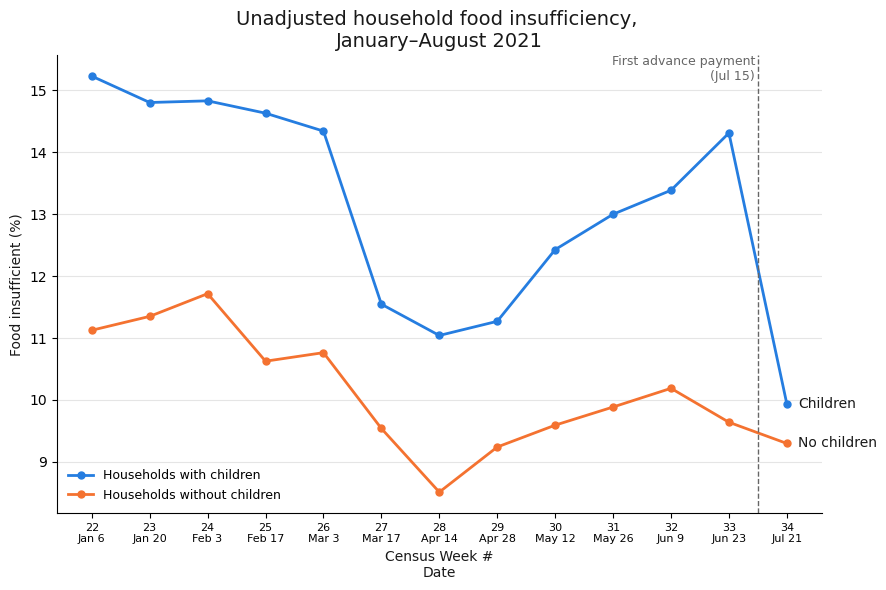

In [27]:
BLUE, ORANGE, INK, MUTED, GRID = "#257de0", "#f47230", "#191919", "#666666", "#e5e5e5"

fig, ax = plt.subplots(figsize=(9, 6))
x = rates.index.values
for col, color in [("Children", BLUE), ("No children", ORANGE)]:
    ax.plot(x, rates[col], color=color, lw=2, marker="o", ms=5, label=f"Households with {col.lower()}" if col == "Children" else "Households without children")
    ax.annotate(col, (x[-1], rates[col].iloc[-1]), xytext=(8, 0), textcoords="offset points",
                va="center", color=INK, fontsize=10)
ax.axvline(33.5, color=MUTED, ls="--", lw=1)
ax.text(33.45, ax.get_ylim()[1], "First advance payment\n(Jul 15)", ha="right", va="top", color=MUTED, fontsize=9)
ax.set_xticks(x, [f"{w}\n{analysis.WEEK_START[w]}" for w in x], fontsize=8)
ax.set_ylabel("Food insufficient (%)", color=INK)
ax.set_xlabel("Census Week #\nDate", color=INK)
ax.set_title("Unadjusted household food insufficiency, \nJanuary–August 2021", loc="center", color=INK, fontsize=14)
ax.grid(axis="y", color=GRID, lw=0.8); ax.set_axisbelow(True)
for s in ("top", "right"): ax.spines[s].set_visible(False)
ax.legend(frameon=False, loc="lower left", fontsize=9)
fig.tight_layout()
FIG_DIR = ROOT / "figures"
FIG_DIR.mkdir(exist_ok=True)
fig.savefig(FIG_DIR / "unadjusted_food_insufficiency.png", dpi=300, bbox_inches="tight")
plt.show()

## 2. Pooled difference-in-differences

`kids_post` = 1 for households with children in week 34. Its coefficient is the change in food insufficiency for households with children after the payment, relative to the change for households without children. `post` itself is absorbed by the wave fixed effects. **Target: −0.022 (P = .001).**

In [4]:
did = analysis.fit_wls(analysis.did_formula(), a)
did_ci = did.conf_int().loc["kids_post"]
print(f"DiD (kids_post): {did.params['kids_post']:.4f}  95% CI {did_ci[0]:.4f} to {did_ci[1]:.4f}  "
      f"p = {did.pvalues['kids_post']:.4f}   (paper: −0.022, P = .001)")

DiD (kids_post): -0.0221  95% CI -0.0340 to -0.0103  p = 0.0002   (paper: −0.022, P = .001)


## 3. Event study

The children indicator is interacted with every wave, with week 33 as the reference. Each coefficient is the gap between households with and without children in that wave, relative to the gap in week 33. β₃₄ is the estimate of interest. **Target: −0.037 (95% CI −0.055 to −0.019).**

In [5]:
es = analysis.fit_wls(analysis.event_study_formula(), a)
es_table = analysis.event_study_table(es)
es_table.round(4)

,week,coef,se,lo,hi,p,start
0,22,-0.0092,0.0086,-0.0261,0.0077,0.2851,Jan 6
1,23,-0.0095,0.0117,-0.0323,0.0134,0.4167,Jan 20
2,24,-0.0157,0.0113,-0.0378,0.0064,0.1645,Feb 3
3,25,-0.0082,0.0063,-0.0206,0.0042,0.1935,Feb 17
4,26,-0.0130,0.0077,-0.0282,0.0021,0.0914,Mar 3
5,27,-0.0230,0.0062,-0.0352,-0.0108,0.0002,Mar 17
6,28,-0.0226,0.0087,-0.0396,-0.0056,0.0090,Apr 14
7,29,-0.0264,0.0094,-0.0447,-0.0080,0.0049,Apr 28
8,30,-0.0199,0.0088,-0.0371,-0.0027,0.0237,May 12
9,31,-0.0164,0.0077,-0.0314,-0.0013,0.0327,May 26


In [6]:
b34 = es_table.set_index("week").loc[34]
inside = -0.055 <= b34.coef <= -0.019
print(f"β34 = {b34.coef:.4f}  95% CI {b34.lo:.4f} to {b34.hi:.4f}  p = {b34.p:.4g}")
print("Point estimate inside the paper's 95% CI:", inside)

β34 = -0.0367  95% CI -0.0543 to -0.0191  p = 4.296e-05
Point estimate inside the paper's 95% CI: True


## 4. Parallel trends

The event-study design assumes that, without the payment, food insufficiency would have moved in parallel for households with and without children. The pre-period coefficients (weeks 22–32) are the check: they should sit near zero with no trend. The joint F-test asks whether they are all zero together.

In [7]:
pt = analysis.pretrend_test(es)
print(f"Joint test that weeks 22–32 coefficients are all zero: F = {float(np.squeeze(pt.fvalue)):.2f}, p = {float(pt.pvalue):.4f}")

Joint test that weeks 22–32 coefficients are all zero: F = 3.46, p = 0.0013


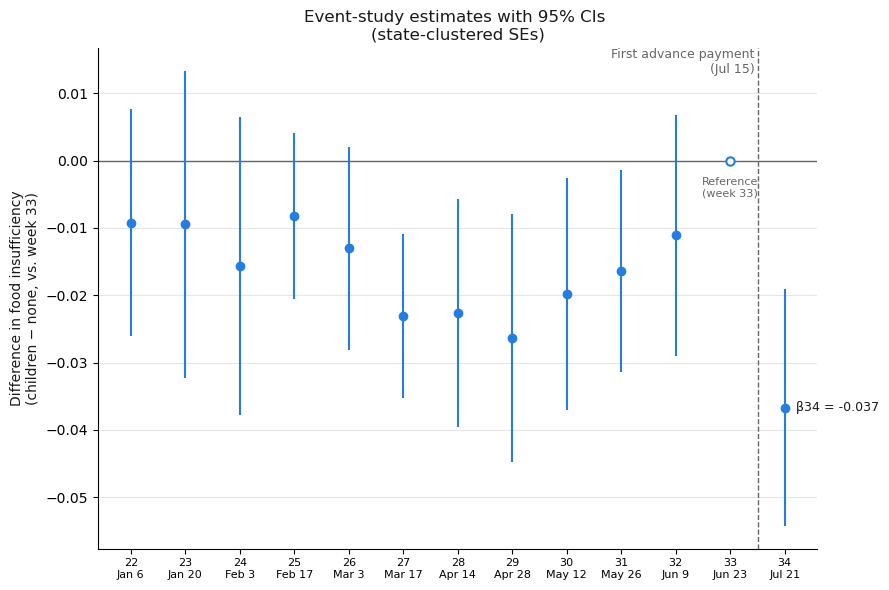

In [29]:
t = es_table
fig, ax = plt.subplots(figsize=(9, 6))
ax.axhline(0, color=MUTED, lw=1)
ax.axvline(33.5, color=MUTED, ls="--", lw=1)
est = t[t.week != analysis.REF_WEEK]
ax.errorbar(est.week, est.coef, yerr=[est.coef - est.lo, est.hi - est.coef], fmt="o", ms=6,
            color=BLUE, ecolor=BLUE, elinewidth=1.5, capsize=0)
ax.plot([analysis.REF_WEEK], [0], "o", ms=6, mfc="white", mec=BLUE, mew=1.5)
ax.annotate("Reference\n(week 33)", (analysis.REF_WEEK, 0), xytext=(0, -26), textcoords="offset points",
            ha="center", color=MUTED, fontsize=8)
ax.annotate(f"β34 = {b34.coef:.3f}", (34, b34.coef), xytext=(8, 0), textcoords="offset points",
            va="center", color=INK, fontsize=9)
ax.text(33.45, ax.get_ylim()[1], "First advance payment\n(Jul 15)", ha="right", va="top", color=MUTED, fontsize=9)
ax.set_xticks(t.week, [f"{w}\n{s}" for w, s in zip(t.week, t.start)], fontsize=8)
ax.set_ylabel("Difference in food insufficiency\n(children − none, vs. week 33)", color=INK)
ax.set_title("Event-study estimates with 95% CIs \n(state-clustered SEs)", loc="center", color=INK)
ax.grid(axis="y", color=GRID, lw=0.8); ax.set_axisbelow(True)
for s in ("top", "right"): ax.spines[s].set_visible(False)
fig.tight_layout()
FIG_DIR = ROOT / "figures"
FIG_DIR.mkdir(exist_ok=True)
fig.savefig(FIG_DIR / "event_study_estimates.png", dpi=300, bbox_inches="tight")
plt.show()

## 5. Robustness: logistic difference-in-differences

The linear probability model can predict values outside 0–1. As a check, the same DiD is fit as a weighted logistic regression, and the effect is converted back to probability units (the average marginal effect of `kids_post` among households with children in week 34) so it is comparable with the estimate above.

In [9]:
fitted = did.fittedvalues
print(f"LPM fitted values outside [0, 1]: {((fitted < 0) | (fitted > 1)).mean():.1%}")

logit, ame = analysis.did_logit_ame(a)
print(f"Logistic DiD, average marginal effect of kids_post: {ame:.4f}   (LPM: {did.params['kids_post']:.4f})")

LPM fitted values outside [0, 1]: 27.8%


c:\Users\Rosey\anaconda3\envs\CSS211\Lib\site-packages\statsmodels\genmod\generalized_linear_model.py:1488: SpecificationWarning: cov_type not fully supported with var_weights
  glm_results = GLMResults(


Logistic DiD, average marginal effect of kids_post: -0.0213   (LPM: -0.0221)


## 6. Replication summary

In [10]:
k = a[a.kids == 1]
summary = pd.DataFrame([
    ["Analytic sample (n)", "585,170", f"{len(a):,}"],
    ["Unadjusted, children, week 33", "14.3%", f"{rates.loc[33, 'Children']:.1f}%"],
    ["Unadjusted, children, week 34", "9.9%", f"{rates.loc[34, 'Children']:.1f}%"],
    ["Event study β34 (95% CI)", "−0.037 (−0.055 to −0.019)", f"{b34.coef:.3f} ({b34.lo:.3f} to {b34.hi:.3f})"],
    ["Event study β34 p-value", "< .001", f"{b34.p:.4g}"],
    ["DiD (kids_post)", "−0.022", f"{did.params['kids_post']:.3f}"],
    ["DiD p-value", ".001", f"{did.pvalues['kids_post']:.4g}"],
    ["Pre-trend joint test p-value", "—", f"{float(pt.pvalue):.3g}"],
    ["Logistic DiD (AME)", "—", f"{ame:.3f}"],
], columns=["Quantity", "Paper", "Ours"])
summary

,Quantity,Paper,Ours
0,Analytic sample (n),"585,170","585,170"
1,"Unadjusted, children, week 33",14.3%,14.3%
2,"Unadjusted, children, week 34",9.9%,9.9%
3,Event study β34 (95% CI),−0.037 (−0.055 to −0.019),-0.037 (-0.054 to -0.019)
4,Event study β34 p-value,< .001,4.296e-05
5,DiD (kids_post),−0.022,-0.022
6,DiD p-value,.001,0.0002392
7,Pre-trend joint test p-value,—,0.00125
8,Logistic DiD (AME),—,-0.021


## Notes on modeling choices

These are choices the paper's Methods do not fully specify; each is a candidate for a sensitivity check if an estimate misses its target.

- **Age group:** 18–24, 25–44, 45–64, from birth year.
- **Race and ethnicity:** Hispanic (any race), then non-Hispanic White, Black, Asian, and other or multiple races.
- **Number of adults and children:** entered as counts. Number of children can't enter as categories alongside the `kids` indicator, because "0 children" and `kids = 0` would be the same variable.
- **Missing-as-category:** income, health insurance, SNAP, food aid and employment keep missing (−1) as a separate category, which is how the analytic sample was reproduced (see `data_prep.ipynb`).
- **Health insurance:** one variable, covered by any type vs. none.

**Next:** `extensions.ipynb` for Extension (b), replicate-weight standard errors, and Extension (a), the state mixed model.